In [18]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay)

train = pd.read_csv("../data/processed/ISOT/train.csv")
val   = pd.read_csv("../data/processed/ISOT/val.csv")
test  = pd.read_csv("../data/processed/ISOT/test.csv")

print(train.shape, val.shape, test.shape)
print(train["label"].value_counts(normalize=True))

(30911, 2) (3864, 2) (3864, 2)
label
1    0.548122
0    0.451878
Name: proportion, dtype: float64


In [19]:
print(train.isnull().sum())
print(val.isnull().sum())
print(test.isnull().sum())

clean_text    0
label         0
dtype: int64
clean_text    0
label         0
dtype: int64
clean_text    0
label         0
dtype: int64


In [20]:
train.dropna()
val.dropna()
test.dropna()

,clean_text,label
0,UK Lords appoint first woman to historic 'Blac...,1
1,"Brazil's Temer to shuffle cabinet in March, ma...",1
2,WHOA! NEW SHOCK POLL Shows Iowa Voters Are Shi...,0
3,Special Counsel Mueller filing shows Manafort ...,1
4,(VIDEO) INNOCENT UNTIL PROVEN GUILTY? AIR FORC...,0
...,...,...
3859,Vietnam court jails blogger for seven years fo...,1
3860,House ethics panel probing Rep. Farenthold ove...,1
3861,Democrats to sue Arizona officials over primar...,1
3862,Trump says he's likely to sign healthcare orde...,1


In [21]:
print(train.isnull().sum())
print(val.isnull().sum())
print(test.isnull().sum())

clean_text    0
label         0
dtype: int64
clean_text    0
label         0
dtype: int64
clean_text    0
label         0
dtype: int64


In [22]:
vec = TfidfVectorizer(max_features=50_000, ngram_range=(1, 2),min_df=2, sublinear_tf=True , stop_words="english")

X_train = vec.fit_transform(train["clean_text"])   
X_val   = vec.transform(val["clean_text"])
X_test  = vec.transform(test["clean_text"])

In [23]:
clf = LogisticRegression(max_iter=1000, C=1.0)
clf.fit(X_train, train["label"])

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

val: acc=0.9904  P=0.9909  R=0.9898  F1=0.9903
test: acc=0.9881  P=0.9885  R=0.9875  F1=0.9880
              precision    recall  f1-score   support

        fake       0.99      0.98      0.99      1738
        real       0.99      0.99      0.99      2126

    accuracy                           0.99      3864
   macro avg       0.99      0.99      0.99      3864
weighted avg       0.99      0.99      0.99      3864



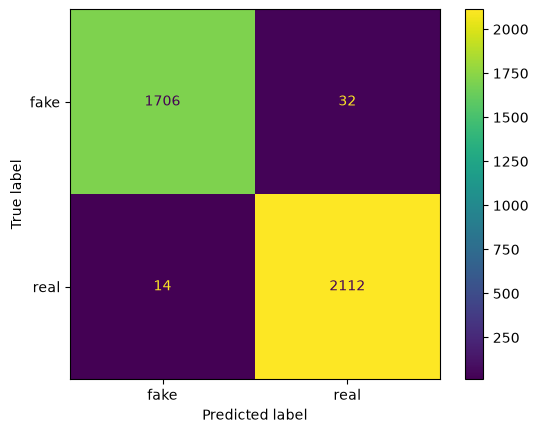

In [24]:
def evaluate(X, y, name):
    pred = clf.predict(X)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro")
    print(f"{name}: acc={accuracy_score(y, pred):.4f}  P={p:.4f}  R={r:.4f}  F1={f1:.4f}")
    return pred

evaluate(X_val, val["label"], "val")
pred = evaluate(X_test, test["label"], "test")

print(classification_report(test["label"], pred, target_names=["fake", "real"]))
ConfusionMatrixDisplay.from_predictions(test["label"], pred, display_labels=["fake", "real"])
plt.show()

In [25]:
names = np.array(vec.get_feature_names_out())
order = np.argsort(clf.coef_[0])

print("Top FAKE words:", names[order[:25]])
print("Top REAL words:", names[order[-25:]])

Top FAKE words: ['video' 'just' 'image' 'featured image' 'featured' 'read' 'gop' 'obama'
 'president trump' 'america' 'watch' 'getty' 'getty images' 'hillary'
 'images' 'com' 'president obama' 'breaking' 'like' 'mr' 'sen'
 'twitter com' 'pic' 'pic twitter' 'american']
Top REAL words: ['government' 'percent' 'year' 'reporters' 'comment' 'presidential'
 'democratic' 'president barack' 'spokesman' 'told reuters'
 'said statement' 'republican' 'monday' 'nov' 'friday' 'minister'
 'reuters president' 'thursday' 'tuesday' 'wednesday' 'washington'
 'president donald' 'washington reuters' 'said' 'reuters']


In [26]:
p, r, f1, _ = precision_recall_fscore_support(test['label'], pred, average="macro")

os.makedirs("../outputs/results", exist_ok=True)
res = {
       "model": "tfidf_logreg",
       "dataset": "fake_news_dataset",
       "test_accuracy": accuracy_score(test["label"], pred),
       "precision" : p,
       "recall" : r,
       "f1_score" : f1
       }
json.dump(res, open("../outputs/results/baseline_isot.json", "w"), indent=2)